In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
iris = load_iris()

X = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

y = iris.target

print("Dataset loaded successfully!")
print("Dataset shape:", X.shape)
print("Flower classes:", iris.target_names)

display(X.head())

Dataset loaded successfully!
Dataset shape: (150, 4)
Flower classes: ['setosa' 'versicolor' 'virginica']


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [4]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [5]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

f1 = f1_score(
    y_test,
    y_pred,
    average="weighted"
)

print("Accuracy:", round(accuracy, 4))
print("F1 Score:", round(f1, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9333
F1 Score: 0.9333

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



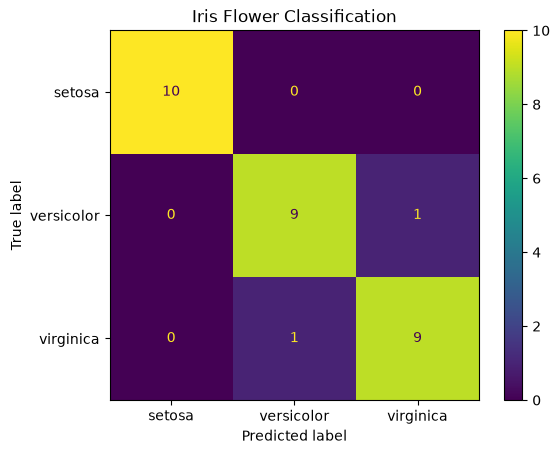

In [6]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=iris.target_names
)

plt.title("Iris Flower Classification")
plt.show()

In [7]:
import os

os.makedirs("../data", exist_ok=True)

iris_df = X.copy()
iris_df["target"] = y

iris_df.to_csv("../data/iris.csv", index=False)

print("Iris dataset saved successfully!")

Iris dataset saved successfully!


In [8]:
import os

print("Notebook location:", os.getcwd())
print("Dataset location:", os.path.abspath("../data/iris.csv"))
print("File exists:", os.path.exists("../data/iris.csv"))

Notebook location: D:\MLOPS\ML-Reproducibility
Dataset location: D:\MLOPS\data\iris.csv
File exists: True
